# SCRFD — Face Detection & Alignment no WIDER Face

Implementação simplificada: o **notebook executa `scrfd_widerface.py`** e visualiza os resultados. O SCRFD-10GF (`buffalo_l`, detection only) produz bounding boxes, scores e 5 landmarks. O alinhamento cria crops **112 × 112**.

A avaliação usa as anotações **WIDER Face Validation (3226 imagens)**: **AP@IoU 0.5**, Precision, Recall, F1, tempos de inferência e robustez. A AP é **personalizada, não a AP oficial Easy/Medium/Hard**. Como não existem landmarks GT no WIDER, o alinhamento é inspecionado visualmente.

In [1]:
# Executar apenas uma vez (reiniciar o kernel depois da instalação).
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


## 1. Configuração
`LIMIT=20` processa as primeiras 20 imagens **originais**, podendo guardar muitos crops por imagem. Para a avaliação final, usar `LIMIT=0`.

In [2]:
from pathlib import Path
import json, subprocess, sys

LIMIT = 20               # 0 = todas as 3226 imagens
DEVICE = 'auto'         # auto, cpu, cuda
DET_SIZE = 640
DET_THRESH = 0.05       # baixo para avaliar AP
EVAL_THRESH = 0.50      # para precision/recall/robustez/crops
IOU_THRESH = 0.50
DOWNLOAD = True         # False se tiveres os 2 ZIPs em data/

OUTPUT = Path('results/scrfd_wider_full' if LIMIT == 0 else f'results/scrfd_wider_limit{LIMIT}')
cmd = [sys.executable, 'scrfd_widerface.py', '--limit', str(LIMIT),
       '--device', DEVICE, '--det-size', str(DET_SIZE),
       '--det-thresh', str(DET_THRESH), '--eval-thresh', str(EVAL_THRESH),
       '--iou-thresh', str(IOU_THRESH), '--output', str(OUTPUT)]
if DOWNLOAD:
    cmd.append('--download')
else:
    cmd += ['--images-zip', 'data/WIDER_val.zip',
            '--annotations-zip', 'data/wider_face_split.zip']
print('Output:', OUTPUT)
print('Command:', ' '.join(cmd))

Output: results\scrfd_wider_limit20
Command: c:\Users\guilh\miniconda3\envs\cvc-a2\python.exe scrfd_widerface.py --limit 20 --device auto --det-size 640 --det-thresh 0.05 --eval-thresh 0.5 --iou-thresh 0.5 --output results\scrfd_wider_limit20 --download


## 2. Executar deteção, alinhamento e avaliação
O `scrfd_widerface.py` é o único ficheiro que implementa o processamento. **As subpastas de resultados gerados são substituídas** ao repetir na mesma diretoria.

In [3]:
subprocess.run(cmd, check=True)

CompletedProcess(args=['c:\\Users\\guilh\\miniconda3\\envs\\cvc-a2\\python.exe', 'scrfd_widerface.py', '--limit', '20', '--device', 'auto', '--det-size', '640', '--det-thresh', '0.05', '--eval-thresh', '0.5', '--iou-thresh', '0.5', '--output', 'results\\scrfd_wider_limit20', '--download'], returncode=0)

## 3. Métricas da deteção
Não apresentamos uma "accuracy" de classificação tradicional: em deteção, os verdadeiros negativos não são definidos como uma classe de faces. **AP, Precision, Recall e F1** medem a qualidade da deteção.

In [4]:
import pandas as pd
from IPython.display import display
m = json.loads((OUTPUT / 'metrics.json').read_text(encoding='utf-8'))
e = m['evaluation']
t = m['timing']['detection_only_inference_ms']
print('Modelo:', m['model'], '| provider:', m['inference_providers'])
print('Imagens processadas:', m['images_processed'], '| GT faces:', m['ground_truth_faces'])
print(f"AP@IoU=0.5 (custom): {e['AP_at_IoU_threshold']:.4f}")
print(f"Precision: {e['precision']:.4f} | Recall: {e['recall']:.4f} | F1: {e['f1']:.4f}")
print(f"TP={e['TP']} | FP={e['FP']} | FN={e['FN']}")
print(f"Inference (ms): mean={t['mean_ms']:.2f}, median={t['median_ms']:.2f}, p95={t['p95_ms']:.2f}")
print('Crops alinhados:', m['alignment']['crops_saved'])

Modelo: SCRFD-10GF / buffalo_l (detection only) | provider: ['CPUExecutionProvider']
Imagens processadas: 20 | GT faces: 816
AP@IoU=0.5 (custom): 0.7466
Precision: 0.9648 | Recall: 0.5368 | F1: 0.6898
TP=438 | FP=16 | FN=378
Inference (ms): mean=46.98, median=45.97, p95=57.53
Crops alinhados: 454


## 4. Accuracy e robustez por condição
Recall das faces do ground truth em função de dimensão, pose, oclusão e múltiplas faces, ao mesmo threshold. Para amostras pequenas, grupos sem exemplos não permitem conclusões.

In [5]:
display(pd.read_csv(OUTPUT / "robustness.csv"))

,group,n_gt,detected,recall
0,all faces,816,438,0.536765
1,tiny (<16 px),463,154,0.332613
2,small (<32 px),731,360,0.492476
3,medium (32-127 px),82,75,0.914634
4,large (>=128 px),3,3,1.000000
5,typical pose,789,433,0.548796
6,atypical pose,27,5,0.185185
7,no occlusion,553,363,0.656420
8,partial occlusion,171,67,0.391813
9,heavy occlusion,92,8,0.086957


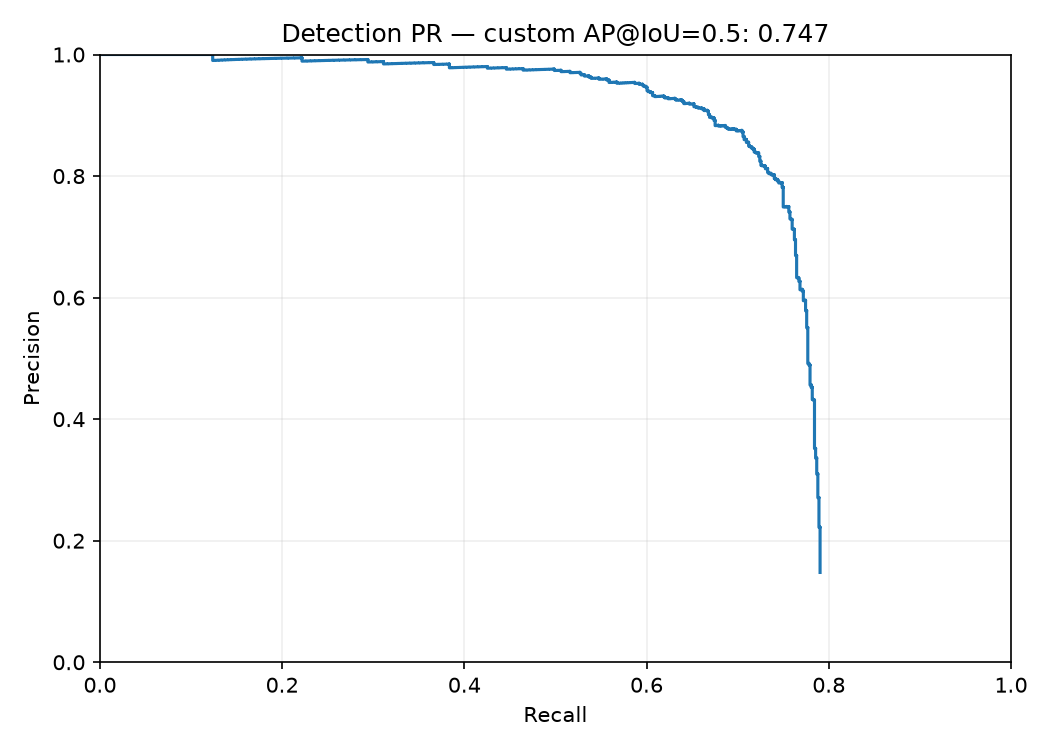

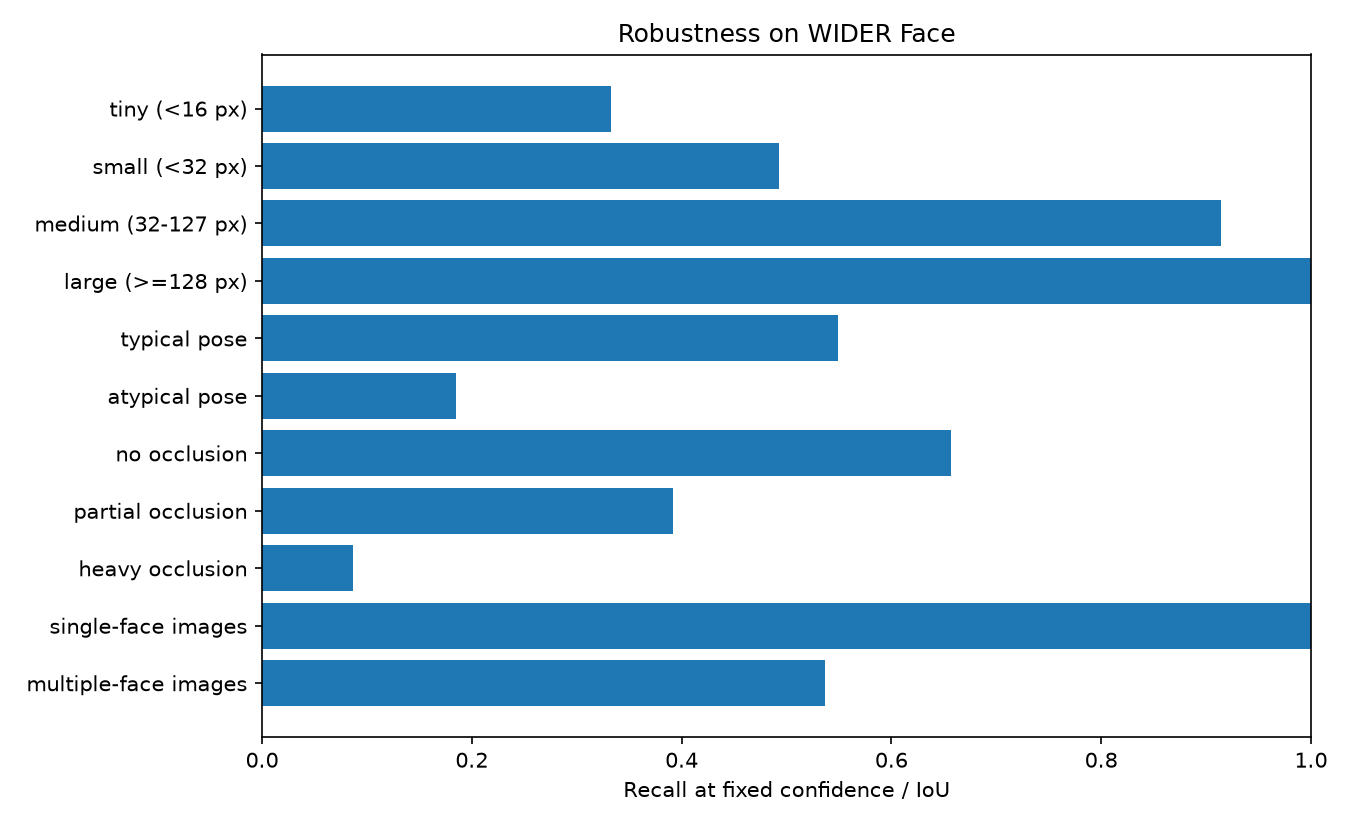

In [6]:
from IPython.display import Image as IPyImage
for f in ('precision_recall.png', 'robustness.png'):
    display(IPyImage(filename=str(OUTPUT / f), width=760))

## 5. Exemplos: deteção + face alignment
Nas visualizações: **azul/laranja** = ground truth; **verde** = SCRFD; **vermelho** = landmarks. Os crops vêm dos 5 landmarks via transformação de similaridade.

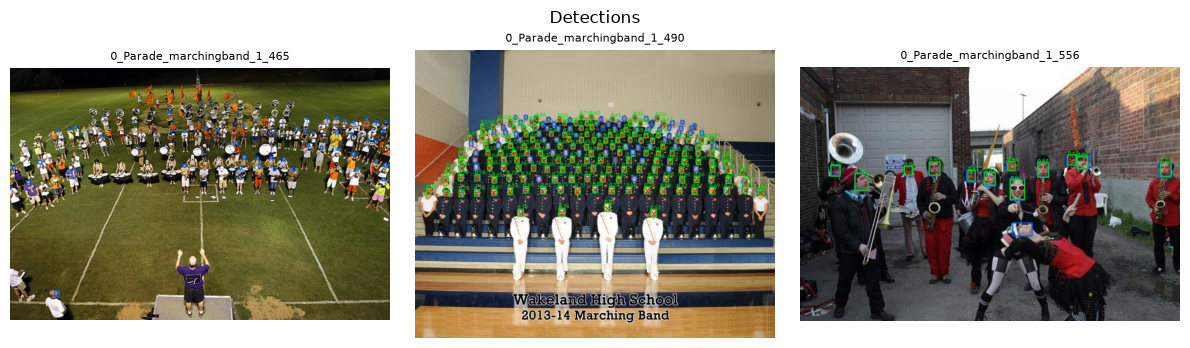

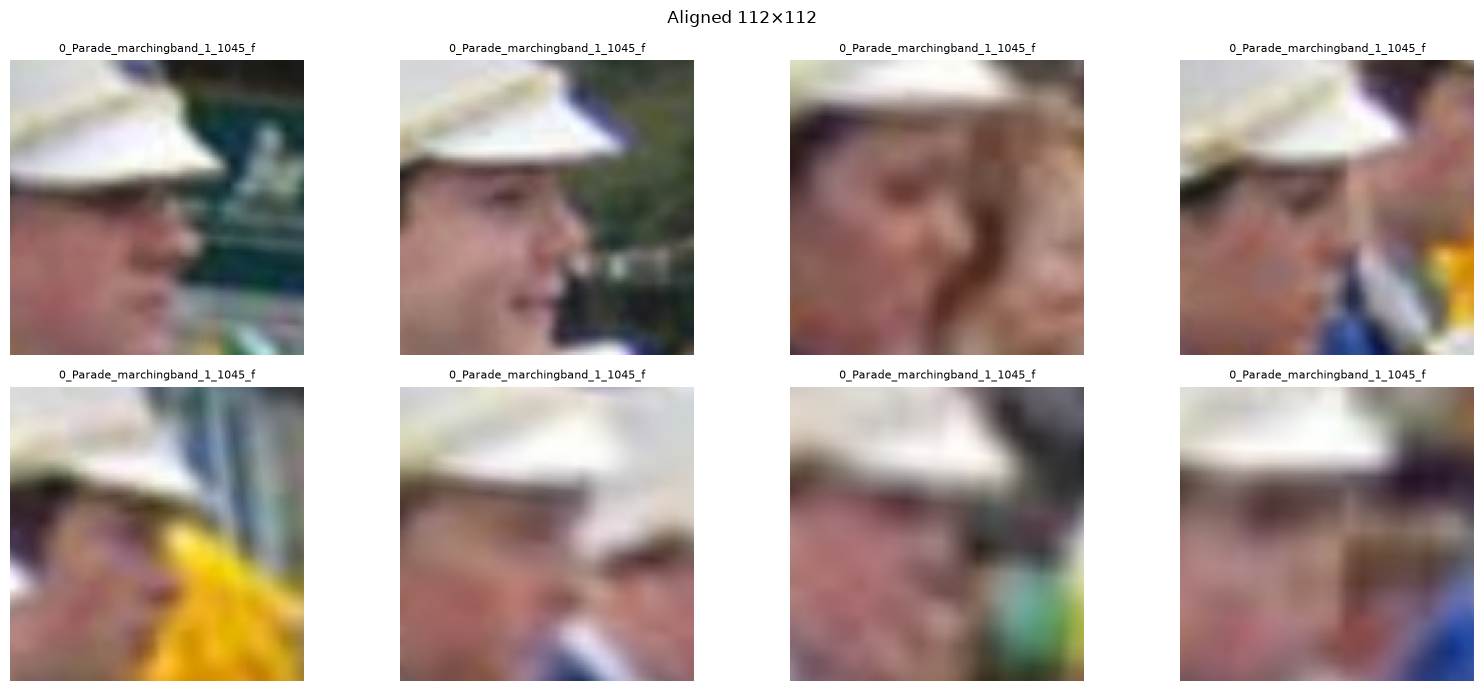

In [7]:
from PIL import Image
import matplotlib.pyplot as plt

previews = list(sorted((OUTPUT / 'visualizations').rglob('*.jpg')))[:3]
crops = list(sorted((OUTPUT / 'aligned_faces').rglob('*.jpg')))[:8]
for title, paths, cols in [('Detections', previews, 3), ('Aligned 112×112', crops, 4)]:
    if not paths:
        print(f'{title}: sem imagens para mostrar')
        continue
    rows = (len(paths) + cols - 1) // cols
    fig, ax = plt.subplots(rows, cols, figsize=(4*cols, 3.5*rows), squeeze=False)
    for a in ax.flat: a.axis('off')
    for a, file in zip(ax.flat, paths):
        a.imshow(Image.open(file))
        a.set_title(file.stem[:30], fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()